[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/pandas-cleaning.ipynb)

# pandas: Cleaning and Types

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Audit missingness and find out why values are missing before filling them.</li>
<li>Convert text columns to numbers, booleans and dates without silently losing data.</li>
<li>Parse numbers out of text, handling the edge cases first.</li>
<li>Package cleaning as a repeatable, tested function.</li>
</ul>
</div>

**Prerequisites:** <a href="../pandas-basics/">pandas: Series, DataFrames and Selection</a>. **Dataset:** Inside Airbnb (London). **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_airbnb, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Raw data arrives with numbers stored as text, dates as strings, categories spelled as `'t'` and `'f'`, whole columns that are empty, and gaps that are not what they seem. Cleaning is mostly **converting types correctly and understanding why values are missing**. pandas has a method for each job.

We work on the London Airbnb listings again, with a goal in mind: a tidy table in which price can be analysed. Right now it cannot even be averaged.

In [2]:
airbnb = load_airbnb()
print(airbnb[["price", "bathrooms_text", "last_review", "host_is_superhost", "amenities"]].head(3).to_string())
print("\nprice dtype:", airbnb["price"].dtype)
try:
    airbnb["price"].mean()
except Exception as e:
    print("mean of price ->", type(e).__name__, ":", str(e)[:70])

     price bathrooms_text last_review host_is_superhost                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  amenities
0  $267.50         1 bath  2026-09-04                 f              

The price column is text (`'$267.50'`), so it has no mean. Let us work through the table in order: first *what is empty*, then *how to convert*, then *why things are missing*.

## 1. Audit what is missing

Start with the shape of the missingness: which columns are completely empty, and which are partly empty?

In [3]:
null_share = airbnb.isna().mean().sort_values(ascending=False)
all_empty = null_share[null_share == 1.0].index.tolist()
print(f"{len(all_empty)} of {airbnb.shape[1]} columns are completely empty:")
print(", ".join(all_empty))

partly = null_share[(null_share > 0) & (null_share < 1)].head(8)
(partly * 100).round(1).to_frame("% missing")

15 of 90 columns are completely empty:
neighbourhood, instant_bookable, host_response_rate, bathrooms, host_acceptance_rate, host_since, host_thumbnail_url, host_neighbourhood, license, host_total_listings_count, host_verifications, neighborhood_overview, neighbourhood_group_cleansed, calendar_updated, host_response_time


,% missing
source,64.90
host_about,46.40
price_quote_total_price,35.00
price_quote_price_per_night,35.00
estimated_revenue_l365d,34.90
price,34.90
price_quote_checkin_date,31.80
price_quote_checkout_date,31.80


Fifteen columns carry no information at all in this snapshot (the data provider evidently stopped publishing host details, among others), so we drop them. Of the rest, price (about a third missing) and the review scores (about a fifth missing) are the big ones.

In [4]:
tidy = airbnb.drop(columns=all_empty)
print("columns kept:", tidy.shape[1])

columns kept: 75


## 2. Converting text to numbers

To convert `'$1,234.50'` to `1234.5`: strip the currency symbol and the thousands comma with `.str.replace`, then convert with `pd.to_numeric`. Always pass `errors="coerce"` so anything unparseable becomes `NaN` *and then count how many that was*, because silent coercion is how data gets lost.

In [5]:
raw_price = tidy["price"]
cleaned = raw_price.str.replace(r"[$,]", "", regex=True)
price = pd.to_numeric(cleaned, errors="coerce")

newly_missing = price.isna().sum() - raw_price.isna().sum()
print(f"values that failed to parse (became NaN because of the conversion): {newly_missing}")
assert newly_missing == 0                              # nothing was silently lost
tidy["price"] = price
print(f"price now {tidy['price'].dtype}; median £{tidy['price'].median():,.0f}; missing {tidy['price'].isna().mean():.1%}")

values that failed to parse (became NaN because of the conversion): 0
price now float64; median £175; missing 34.9%


No value was lost to the conversion, so all the missing prices were *already* missing. Which raises the real question.

## 3. Why is price missing?

Before filling or dropping, ask whether the missingness is **random**. If it is related to something, treating it as random will bias every later result. A good first test is to compare the share missing across a plausible driver. Listings with no availability in the coming year seem a candidate:

In [6]:
unavailable = tidy["availability_365"] == 0
by_availability = tidy.groupby(unavailable.map({True: "no availability in the next year", False: "some availability"}))["price"].apply(lambda s: s.isna().mean())
print((by_availability * 100).round(1).to_string())
print(f"\nlistings with no availability: {unavailable.mean():.1%} of all;  share of ALL missing prices that belong to them: {(unavailable & tidy['price'].isna()).sum() / tidy['price'].isna().sum():.1%}")

availability_365
no availability in the next year   98.90
some availability                   6.40

listings with no availability: 30.8% of all;  share of ALL missing prices that belong to them: 87.3%


There it is: **almost every listing without availability has no price, and almost every listing with availability has one.** The price is missing because the listing is not currently for rent: the gap is *structural*, not random. Consequences:

- Dropping rows with missing prices quietly removes *almost all of the unavailable listings* (they account for the large majority of the gaps), so any "typical London listing" you describe now means "typical currently-bookable listing".
- Filling the gaps with a median would invent prices for listings that are not on the market.

The right choice depends on the question. For *"what do available listings cost?"* dropping is correct, provided you **say so**. For *"describe all listings"* keep the missing values and report them.

## 4. Outliers: look at the extremes before summarising

A mean is only as good as its worst value.

minimum                  £10
1st percentile           £37
median                  £175
99th percentile       £1,272
99.9th percentile     £6,254
maximum              £75,000

listed above £1,000 a night: 982 (1.64%);  mean £248 vs median £175


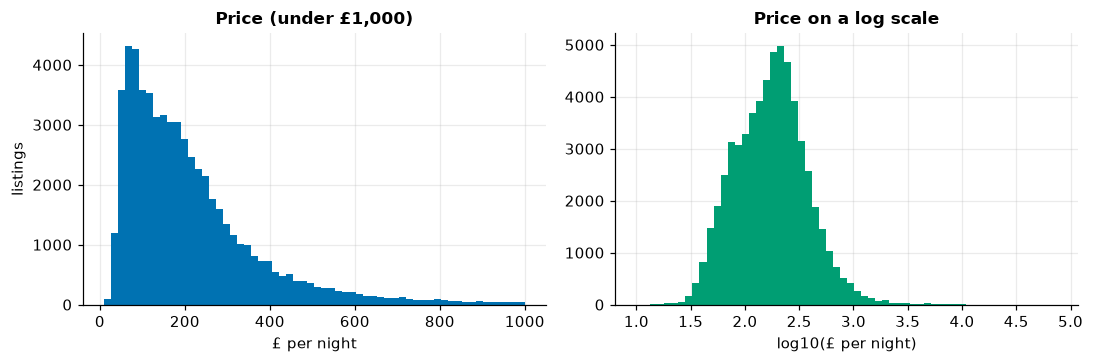

In [7]:
p = tidy["price"].dropna()
quantiles = pd.Series(p.quantile([0, 0.01, 0.5, 0.99, 0.999, 1]).to_numpy(), index=["minimum", "1st percentile", "median", "99th percentile", "99.9th percentile", "maximum"])
print(quantiles.map("£{:,.0f}".format).to_string())
print(f"\nlisted above £1,000 a night: {(p > 1000).sum():,} ({(p > 1000).mean():.2%});  mean £{p.mean():,.0f} vs median £{p.median():,.0f}")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
a.hist(p[p < 1000], bins=60, color=style.BLUE); a.set(title="Price (under £1,000)", xlabel="£ per night", ylabel="listings")
b.hist(np.log10(p), bins=60, color=style.GREEN); b.set(title="Price on a log scale", xlabel="log10(£ per night)")
plt.tight_layout(); plt.show()

The price distribution is strongly right-skewed: the mean sits well above the median, and the largest value is absurdly high (a nightly price of £75,000 is almost certainly a data entry error or a placeholder). On a **log scale** the shape becomes a tidy hump, which is why prices are almost always modelled in logs. Common treatments for extremes: **winsorise** (clip to a percentile), **filter** with a documented rule, or **transform** (log). Whichever you pick, record it.

## 5. Booleans and dates

`'t'`/`'f'` strings become real booleans with a mapping; date strings become datetimes with `pd.to_datetime`, which unlocks the `.dt` accessor.

In [8]:
tidy["host_is_superhost"] = tidy["host_is_superhost"].map({"t": True, "f": False}).astype("boolean")    # nullable boolean keeps real gaps as <NA>
tidy["last_review"] = pd.to_datetime(tidy["last_review"])

snapshot = pd.to_datetime(tidy["last_scraped"]).max()
tidy["days_since_review"] = (snapshot - tidy["last_review"]).dt.days
print(f"snapshot date: {snapshot.date()};  superhosts: {tidy['host_is_superhost'].mean():.1%};  never reviewed: {tidy['last_review'].isna().mean():.1%}")
tidy["days_since_review"].describe().round(0).to_frame("days since last review")

snapshot date: 2026-09-23;  superhosts: 19.4%;  never reviewed: 22.5%


,days since last review
count,"71,260.00"
mean,642.00
std,"1,039.00"
min,1.00
25%,24.00
50%,80.00
75%,754.00
max,"5,294.00"


Note `astype("boolean")`, the *nullable* boolean type: ordinary `bool` cannot hold a missing value, but `boolean` can, which matters for the gaps. The `.dt` accessor then does date arithmetic: subtracting two datetimes gives a timedelta, whose `.dt.days` is a plain number. Listings never reviewed have `NaN` here, correctly: "never reviewed" is information, not an error.

## 6. Parsing numbers out of text

`bathrooms_text` holds values like `'1 shared bath'` and `'Half-bath'`. A regex pulls out the number and a second test gets the flag. Real data has edge cases, so look at the oddities *first*:

In [9]:
text = tidy["bathrooms_text"]
odd = text[~text.str.contains(r"\d", na=False) & text.notna()].value_counts()
print("values with no digit:", odd.to_dict())

number = text.str.extract(r"(\d+\.?\d*)", expand=False).astype(float)         # '2.5 baths' -> 2.5
number = number.where(~(text.str.contains("half", case=False, na=False) & number.isna()), 0.5)   # 'Half-bath' -> 0.5
number = number.where(~(text.str.contains("no bathroom", case=False, na=False)), 0.0)          # 'No bathroom' -> 0
tidy["bathrooms"] = number
tidy["shared_bathroom"] = text.str.contains("shared", case=False, na=False)

print(f"parsed; still missing: {tidy['bathrooms'].isna().sum()} (same as the {text.isna().sum()} that were missing in the text)")
assert tidy["bathrooms"].isna().sum() == text.isna().sum()
tidy[["bathrooms_text", "bathrooms", "shared_bathroom"]].drop_duplicates("bathrooms_text").head(6)

values with no digit: {'Shared half-bath': 460, 'Half-bath': 273, 'Private half-bath': 254, 'No bathroom': 10}
parsed; still missing: 108 (same as the 108 that were missing in the text)


,bathrooms_text,bathrooms,shared_bathroom
0,1 bath,1.00,False
1,1 shared bath,1.00,True
3,1.5 baths,1.50,False
6,2 baths,2.00,False
9,1 private bath,1.00,False
10,2.5 baths,2.50,False


The step before the regex mattered: *'Half-bath'* and *'No bathroom'* contain no digit at all, so the plain pattern would have silently turned them into `NaN`. The final assertion proves we introduced no new gaps.

The same idea counts items in the `amenities` column, a JSON list stored as a string:

In [10]:
import json
tidy["n_amenities"] = tidy["amenities"].map(lambda s: len(json.loads(s)) if isinstance(s, str) else np.nan)
tidy["has_wifi"] = tidy["amenities"].str.contains("wifi", case=False, na=False)
print(f"median amenities per listing: {tidy['n_amenities'].median():.0f};  mention Wifi: {tidy['has_wifi'].mean():.1%}")

median amenities per listing: 29;  mention Wifi: 97.0%


## 7. Keys, duplicates and imputation

Check that the identifier really is unique, then decide how to treat the small remaining gaps. A defensible, simple choice is the **median within a group**: for a missing bed count, the typical value for listings that sleep the same number of guests. `groupby(...).transform(...)` returns a column aligned with the original rows, ready to fill from.

In [11]:
assert tidy["id"].is_unique, "listing ids should be unique"
print("duplicate ids:", tidy["id"].duplicated().sum(), "| fully duplicated rows:", tidy.duplicated().sum())

missing_beds = tidy["beds"].isna().sum()
typical = tidy.groupby("accommodates")["beds"].transform("median")             # per-row: the median beds for that capacity
tidy["beds"] = tidy["beds"].fillna(typical)
print(f"filled {missing_beds:,} missing bed counts with the median for the same capacity; still missing: {tidy['beds'].isna().sum()}")

duplicate ids: 0 | fully duplicated rows: 0
filled 1,990 missing bed counts with the median for the same capacity; still missing: 0


<div class="admonition warning">
<p class="admonition-title">Imputation belongs inside the model pipeline</p>
<p>Filling with a group median computed on the <em>whole</em> table uses information from rows you will later test on. That is harmless for exploration but a <strong>leak</strong> if the table feeds a model. In a modelling workflow use scikit-learn's imputers inside a <code>Pipeline</code>, so medians are learned from training rows only (see the scikit-learn pipelines page).</p>
</div>

## 8. Put it all in one function

Everything above, as a single repeatable function: the cleaning you did by hand becomes code you can re-run on next quarter's snapshot, and test.

In [12]:
def clean_airbnb(raw):
    out = raw.drop(columns=raw.columns[raw.isna().all()]).copy()
    out["price"] = pd.to_numeric(out["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
    out["host_is_superhost"] = out["host_is_superhost"].map({"t": True, "f": False}).astype("boolean")
    out["last_review"] = pd.to_datetime(out["last_review"])
    t = out["bathrooms_text"]
    n = t.str.extract(r"(\d+\.?\d*)", expand=False).astype(float)
    n = n.where(~(t.str.contains("half", case=False, na=False) & n.isna()), 0.5).where(~t.str.contains("no bathroom", case=False, na=False), 0.0)
    out["bathrooms"], out["shared_bathroom"] = n, t.str.contains("shared", case=False, na=False)
    out["neighbourhood_cleansed"] = out["neighbourhood_cleansed"].astype("category")
    out["room_type"] = out["room_type"].astype("category")
    assert out["id"].is_unique
    return out

clean = clean_airbnb(airbnb)
before_after = pd.DataFrame({"before": airbnb[["price", "host_is_superhost", "last_review", "bathrooms", "room_type"]].dtypes.astype(str),
                             "after": clean[["price", "host_is_superhost", "last_review", "bathrooms", "room_type"]].dtypes.astype(str)})
print(f"{airbnb.shape[1]} columns -> {clean.shape[1]}")
before_after

90 columns -> 77


,before,after
price,str,float64
host_is_superhost,str,boolean
last_review,str,datetime64[us]
bathrooms,float64,float64
room_type,str,category


## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| `mean()` fails or concatenates text | numbers stored as strings | strip symbols, `pd.to_numeric(errors="coerce")`, then **count new NaN** |
| Dropping `NaN` rows changes who is in the data | missingness is not random | find the driver *before* dropping or filling |
| A regex silently returns `NaN` | edge cases with no digit | list the oddities first; assert no new gaps |
| `bool` column cannot hold a gap | plain `bool` has no missing value | the nullable `"boolean"` dtype |
| Imputed values leak into the test set | statistics computed on all rows | impute inside a `Pipeline` |

## Check yourself

<details class="question">
<summary>1. Why pass <code>errors="coerce"</code> to <code>to_numeric</code>, and what must you do right after?</summary>

Without it, a single unparseable value raises an error and stops the conversion. With `"coerce"` unparseable values become `NaN` instead. That is convenient but silent, so you must **count the new `NaN`s** (compare with the count before) to be sure you did not quietly destroy data.

</details>

<details class="question">
<summary>2. Prices are missing for almost exactly the listings with no availability. Should you fill them with the median price?</summary>

Not without thought. They are missing because the listing is not on the market, so a filled-in price would be invented. For analyses of *current* prices, drop them and say so; for describing all listings, keep them as missing and report how many. The missingness carries information; filling erases it.

</details>

<details class="question">
<summary>3. Why must <code>'Half-bath'</code> be handled separately from the digit-extracting regex?</summary>

It contains no digit, so `str.extract(r"(\d+\.?\d*)")` returns `NaN` for it, silently converting a real value (half a bathroom) into "missing". Looking at the non-matching values *before* trusting the regex is how you find such edge cases.

</details>

## Exercises

<details class="question">
<summary>How many listings cost more than £1,000 a night, and what share of <em>those</em> are private rooms? Does that match your expectation?</summary>

```python
expensive = clean[clean["price"] > 1000]
print(len(expensive), "listings above £1,000")
print((expensive["room_type"].value_counts(normalize=True) * 100).round(1).to_dict())
```

About 980 listings, and roughly 93% of them are entire homes, with about 7% private rooms. A private room at over £1,000 a night is a much stronger sign of a data error than an entire home at that price, so that small group is where to look first.

</details>

<details class="question">
<summary>Add a column <code>pets_allowed</code> that is True when the amenities mention pets, then compare its median price with the rest.</summary>

```python
clean["pets_allowed"] = clean["amenities"].str.contains("pets allowed", case=False, na=False)
print(clean.groupby("pets_allowed")["price"].median())
```

About 13% of listings allow pets, and their median price is higher (roughly £210 against £168). That is an **association, not an effect**: it plausibly reflects which kinds of listing allow pets rather than pets raising the price. `str.contains(..., na=False)` guards against missing amenity strings, and both medians are computed only over listings that *have* a price.

</details>

## Recap

- **Audit missingness first**: which columns are empty, which are partly empty, and **why**. Structural gaps (price missing because the listing is unavailable) should not be filled blindly.
- Convert text to numbers with `str.replace` + `pd.to_numeric(errors="coerce")`, and **count the new NaNs**.
- Look at extremes before summarising; consider winsorising, filtering or a log transform.
- Use `map` for coded categories, `pd.to_datetime` and `.dt` for dates, the nullable `"boolean"` dtype when gaps matter, and `str.extract` with edge cases checked first.
- Wrap the steps in a **function** you can re-run and test; impute inside a **Pipeline** when a model is involved.

**Next:** *Grouping and merging*, combining tables and summarising by group.